<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bar Charts**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be provided to you in the form of an RDBMS.

You will use SQL queries to extract the necessary data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data

-   Visualize the relationship between two features

-   Visualize the composition of data

-   Visualize comparison of data


## Setup: Working with the Database
**Install the needed libraries**


In [ ]:
!pip install pandas

In [ ]:
!pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [3]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Step 2: Import necessary libraries and load the dataset
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows to understand the structure of the data
df.head()


--2026-11-09 03:06:41--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  42.5MB/s    in 3.8s    

2026-11-09 03:06:45 (40.4 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]



,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("survey-data.csv")

# YearsCodePro cleanup
df['YearsCodePro_num'] = (
    df['YearsCodePro']
    .replace({
        'Less than 1 year': 0,
        'More than 50 years': 51
    })
)

df['YearsCodePro_num'] = pd.to_numeric(
    df['YearsCodePro_num'],
    errors='coerce'
)

# Age order
age_order = [
    'Under 18 years old',
    '18-24 years old',
    '25-34 years old',
    '35-44 years old',
    '45-54 years old',
    '55-64 years old',
    '65 years or older'
]

# Salary outlier removal
salary_df = df.dropna(subset=['ConvertedCompYearly']).copy()

Q1 = salary_df['ConvertedCompYearly'].quantile(0.25)
Q3 = salary_df['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1

salary_df = salary_df[
    (salary_df['ConvertedCompYearly'] >= Q1 - 1.5 * IQR) &
    (salary_df['ConvertedCompYearly'] <= Q3 + 1.5 * IQR)
]

age_map = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 30,
    '35-44 years old': 40,
    '45-54 years old': 50,
    '55-64 years old': 60,
    '65 years or older': 70
}

### Task 1: Visualizing Data Distributions


##### 1. Histogram of `ConvertedCompYearly`


Visualize the distribution of yearly compensation (`ConvertedCompYearly`) using a histogram.



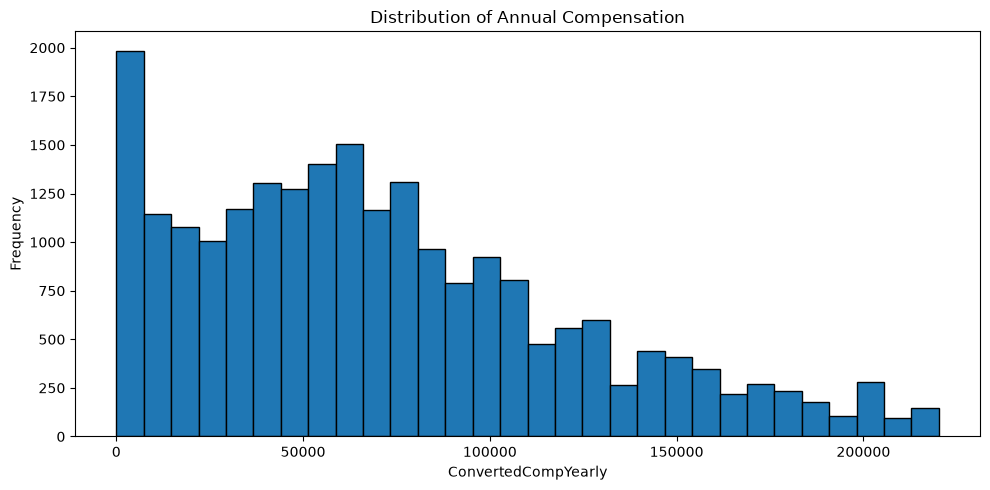

In [5]:
plt.figure(figsize=(10,5))

plt.hist(
    salary_df['ConvertedCompYearly'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Annual Compensation')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

##### 2. Box Plot of `Age`


Since `Age` is categorical in the dataset, convert it to numerical values for a box plot.



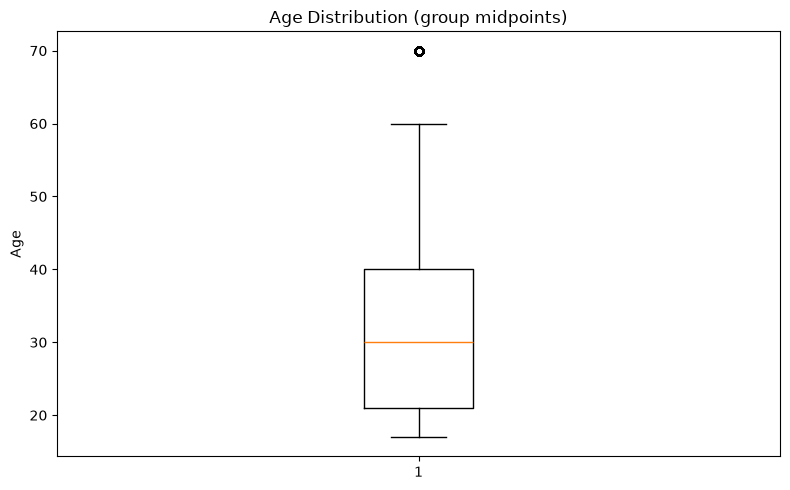

In [6]:
age_num = df['Age'].map(age_map).dropna()
plt.figure(figsize=(8, 5))
plt.boxplot(age_num)
plt.title('Age Distribution (group midpoints)'); plt.ylabel('Age')
plt.tight_layout(); plt.show()

### Task 2: Visualizing Relationships in Data


##### 1. Scatter Plot of `Age_numeric` and `ConvertedCompYearly`


Explore the relationship between age and compensation.



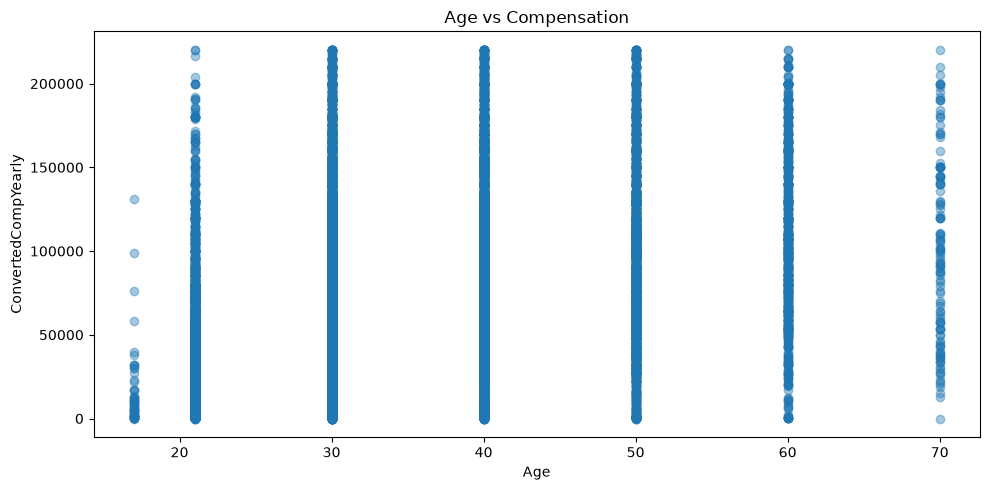

In [7]:
age_map = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 30,
    '35-44 years old': 40,
    '45-54 years old': 50,
    '55-64 years old': 60,
    '65 years or older': 70
}

scatter_df = salary_df.copy()
scatter_df['AgeNum'] = scatter_df['Age'].map(age_map)

plt.figure(figsize=(10,5))

plt.scatter(
    scatter_df['AgeNum'],
    scatter_df['ConvertedCompYearly'],
    alpha=0.4
)

plt.title('Age vs Compensation')
plt.xlabel('Age')
plt.ylabel('ConvertedCompYearly')
plt.tight_layout()
plt.show()

##### 2. Bubble Plot of `ConvertedCompYearly` and `JobSatPoints_6` with `Age_numeric` as Bubble Size


Explore how compensation and job satisfaction are related, with age as the bubble size.


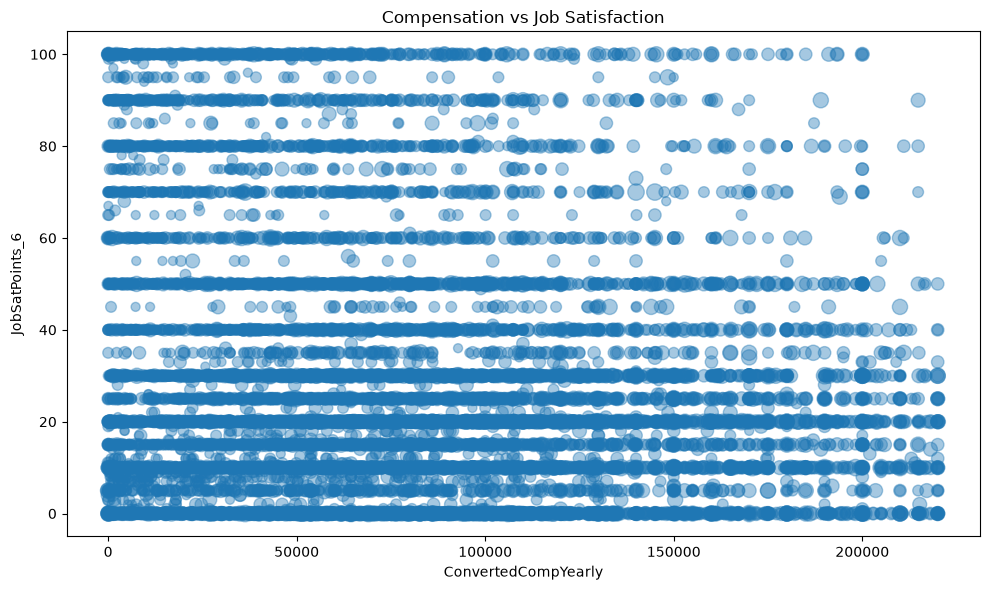

In [8]:
bubble_df = salary_df.copy()

bubble_df['AgeNum'] = bubble_df['Age'].map(age_map)

plt.figure(figsize=(10,6))

plt.scatter(
    bubble_df['ConvertedCompYearly'],
    bubble_df['JobSatPoints_6'],
    s=bubble_df['AgeNum'] * 2,
    alpha=0.4
)

plt.title('Compensation vs Job Satisfaction')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSatPoints_6')
plt.tight_layout()
plt.show()

### Task 3: Visualizing Composition of Data with Bar Charts


##### 1. Horizontal Bar Chart of `MainBranch` Distribution


Visualize the distribution of respondents’ primary roles to understand their professional focus.



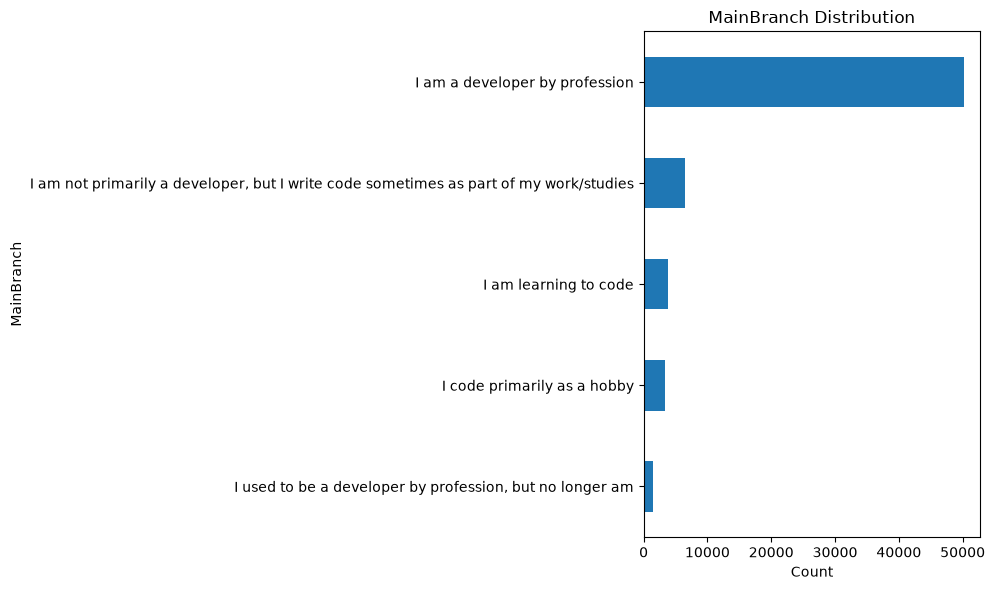

In [9]:
main_branch = (
    df['MainBranch']
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10,6))

main_branch.plot(
    kind='barh'
)

plt.title('MainBranch Distribution')
plt.xlabel('Count')
plt.ylabel('MainBranch')
plt.tight_layout()
plt.show()


##### 2. Vertical Bar Chart of Top 5 Programming Languages Respondents Want to Work With


Identify the most desired programming languages based on `LanguageWantToWorkWith`.



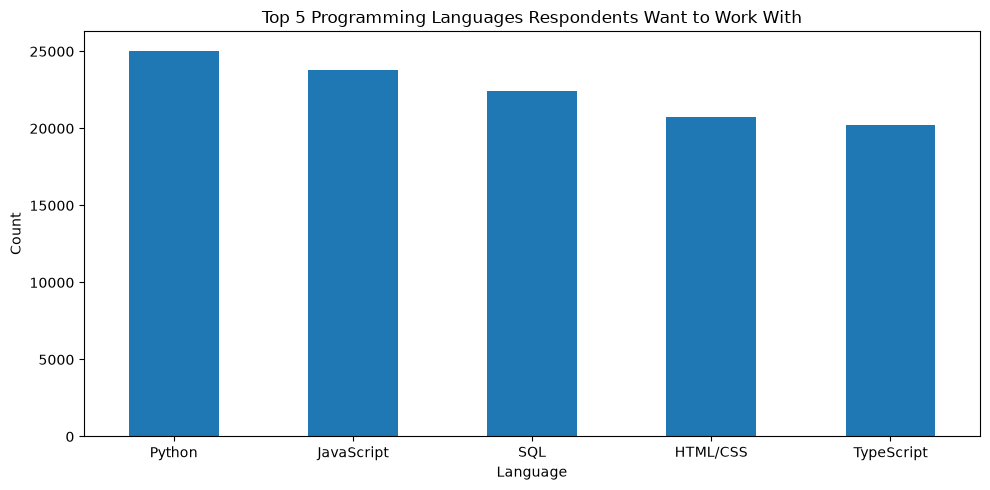

In [10]:
want = df['LanguageWantToWorkWith'].dropna().str.split(';').explode().value_counts().head(5)
plt.figure(figsize=(10, 5))
want.plot(kind='bar')
plt.title('Top 5 Programming Languages Respondents Want to Work With')
plt.xlabel('Language'); plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

##### 3. Stacked Bar Chart of Median `JobSatPoints_6` and `JobSatPoints_7` by Age Group


Compare job satisfaction metrics across different age groups with a stacked bar chart.


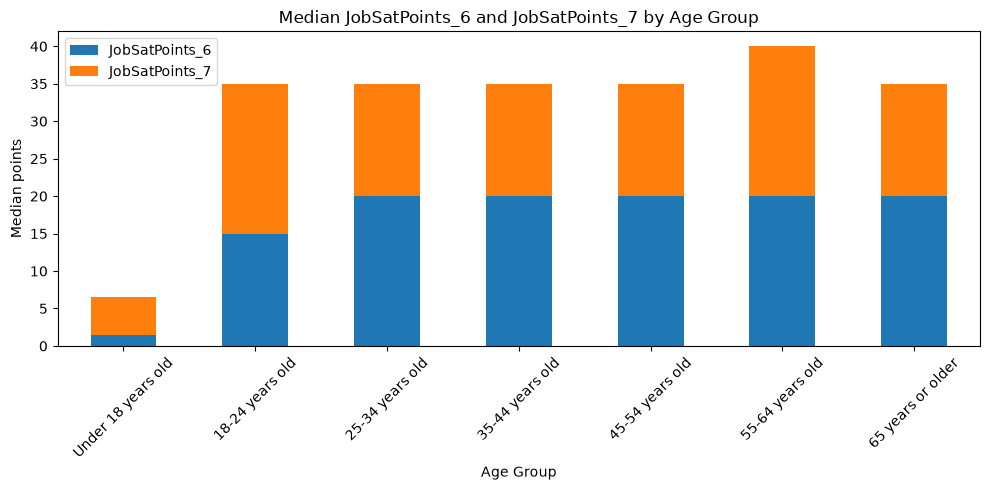

In [11]:
jobsat_age = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median().reindex(age_order)
jobsat_age.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Median JobSatPoints_6 and JobSatPoints_7 by Age Group')
plt.xlabel('Age Group'); plt.ylabel('Median points'); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

##### 4. Bar Chart of Database Popularity (`DatabaseHaveWorkedWith`)


Identify the most commonly used databases among respondents by visualizing `DatabaseHaveWorkedWith`.



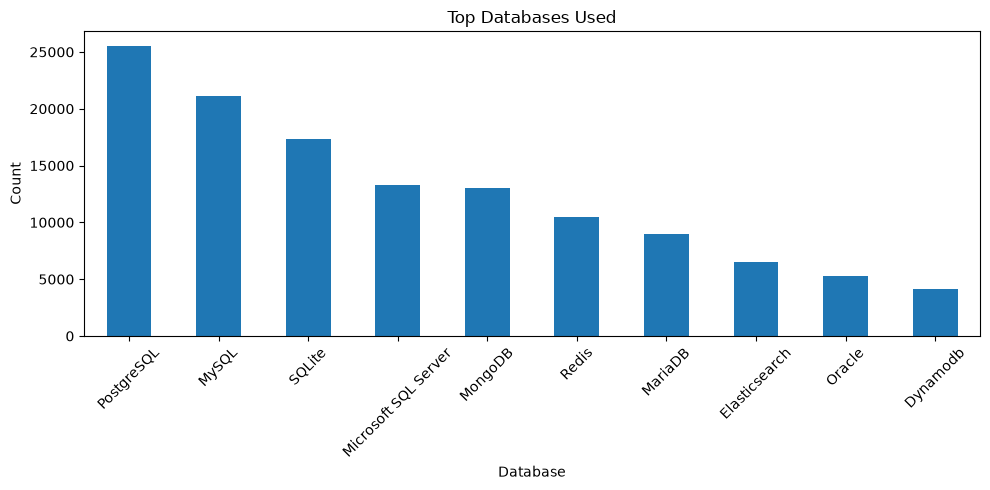

In [12]:
databases = (
    df['DatabaseHaveWorkedWith']
    .dropna()
    .str.split(';')
    .explode()
)

top_databases = databases.value_counts().head(10)

plt.figure(figsize=(10,5))

top_databases.plot(kind='bar')

plt.title('Top Databases Used')
plt.xlabel('Database')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Task 4: Visualizing Comparison of Data with Bar Charts


##### 1. Grouped Bar Chart of Median `ConvertedCompYearly` for Different Age Groups


Compare median compensation across multiple age groups with a grouped bar chart.



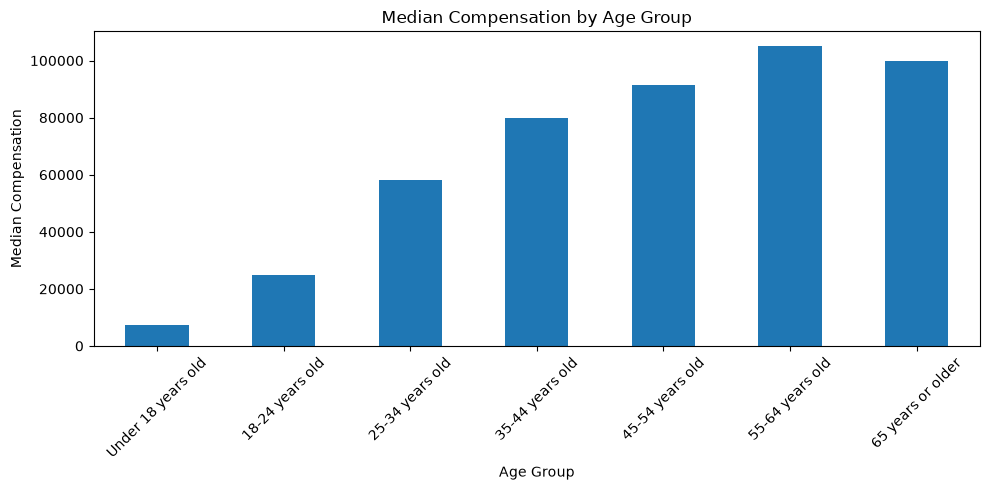

In [13]:
comp_age = (
    salary_df.groupby('Age')['ConvertedCompYearly']
    .median()
    .reindex(age_order)
)

comp_age.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Median Compensation by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Median Compensation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 2. Bar Chart of Respondent Count by Country


Show the distribution of respondents by country to see which regions are most represented.



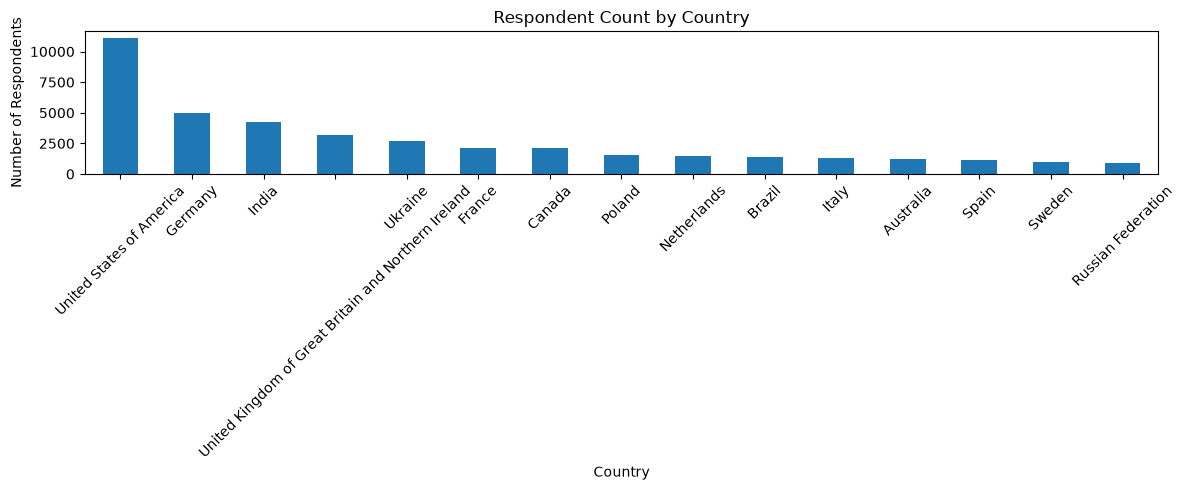

In [14]:
top_countries = df['Country'].value_counts().head(15)

plt.figure(figsize=(12,5))

top_countries.plot(kind='bar')

plt.title('Respondent Count by Country')
plt.xlabel('Country')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Top 10 Languages — Current Year (Have Worked With)
LanguageHaveWorkedWith
JavaScript                 37492
HTML/CSS                   31816
Python                     30719
SQL                        30682
TypeScript                 23150
Bash/Shell (all shells)    20412
Java                       18239
C#                         16318
C++                        13827
C                          12184


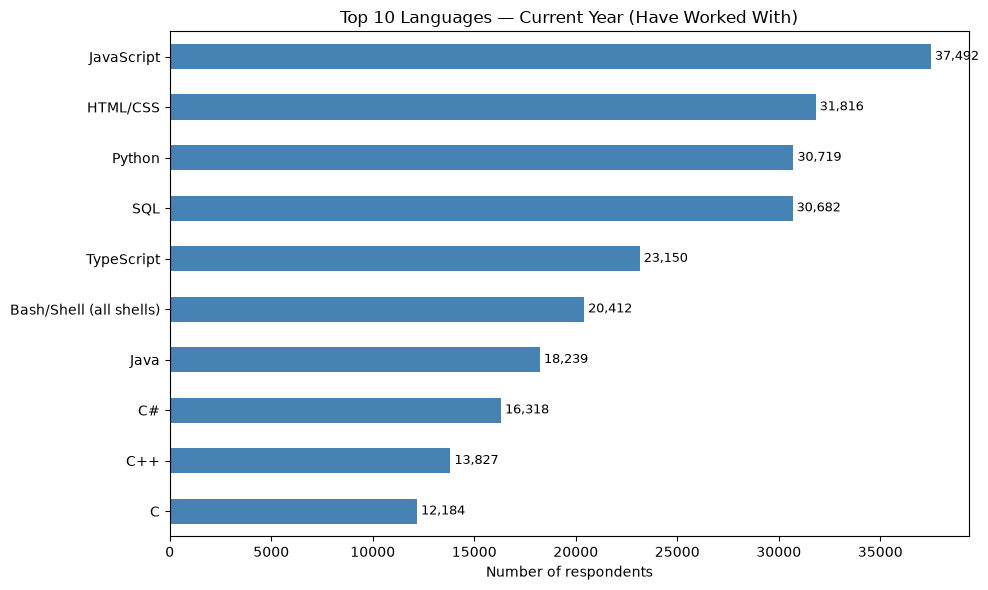


Top 10 Languages — Next Year (Want to Work With)
LanguageWantToWorkWith
Python                     25047
JavaScript                 23774
SQL                        22400
HTML/CSS                   20721
TypeScript                 20239
Rust                       17232
Go                         13837
Bash/Shell (all shells)    13744
C#                         12921
C++                        10873


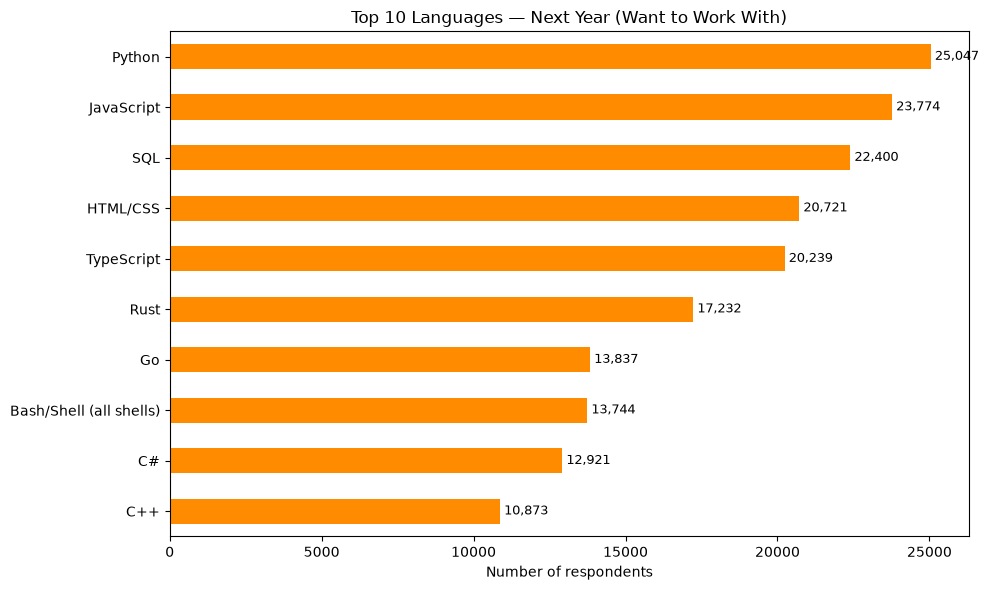


Top 10 Databases — Current Year (Have Worked With)
DatabaseHaveWorkedWith
PostgreSQL              25536
MySQL                   21099
SQLite                  17365
Microsoft SQL Server    13275
MongoDB                 13007
Redis                   10463
MariaDB                  8991
Elasticsearch            6533
Oracle                   5273
Dynamodb                 4138


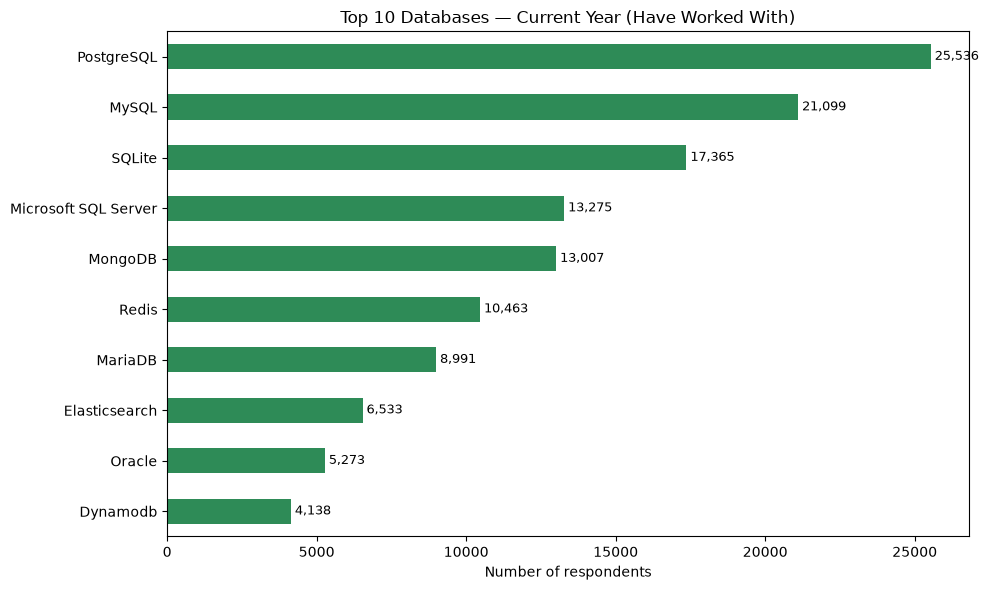


Top 10 Databases — Next Year (Want to Work With)
DatabaseWantToWorkWith
PostgreSQL              24005
SQLite                  13489
MySQL                   12269
MongoDB                 10982
Redis                   10847
Microsoft SQL Server     7905
Elasticsearch            6246
MariaDB                  5947
Dynamodb                 3503
Supabase                 2930


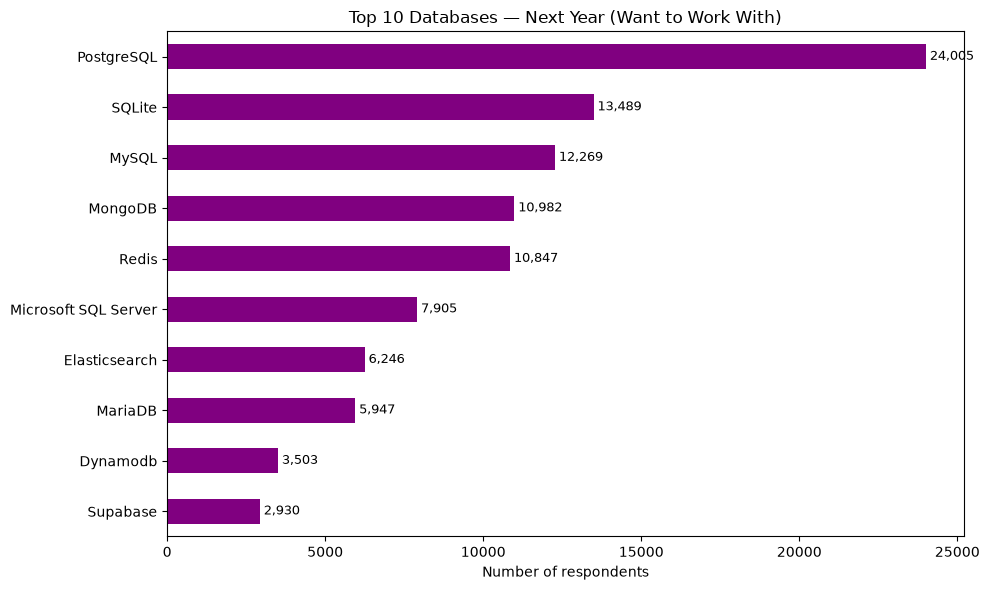

In [15]:
def top10_chart(col, title, color):
    top = df[col].dropna().str.split(';').explode().value_counts().head(10)
    print(f"\n{title}\n{top.to_string()}")
    plt.figure(figsize=(10, 6))
    top.sort_values().plot(kind='barh', color=color)
    plt.title(title); plt.xlabel('Number of respondents'); plt.ylabel('')
    for i, v in enumerate(top.sort_values()):
        plt.text(v, i, f' {v:,}', va='center', fontsize=9)
    plt.tight_layout(); plt.show()

top10_chart('LanguageHaveWorkedWith',  'Top 10 Languages — Current Year (Have Worked With)', 'steelblue')
top10_chart('LanguageWantToWorkWith',  'Top 10 Languages — Next Year (Want to Work With)',  'darkorange')
top10_chart('DatabaseHaveWorkedWith',  'Top 10 Databases — Current Year (Have Worked With)', 'seagreen')
top10_chart('DatabaseWantToWorkWith',  'Top 10 Databases — Next Year (Want to Work With)',   'purple')

### Final Step: Review


This lab demonstrates how to create and interpret different types of bar charts, allowing you to analyze the composition, comparison, and distribution of categorical data in the Stack Overflow dataset, including main professional branches, programming language preferences, and compensation by age group. Bar charts effectively compare counts and median values across various categories.


## Summary


After completing this lab, you will be able to:
- Create a horizontal bar chart to visualize the distribution of respondents' primary roles, helping to understand their professional focus.
- Develop a vertical bar chart to identify the most desired programming languages based on the LanguageWantToWorkWith variable.
- Use a stacked bar chart to compare job satisfaction metrics across different age groups.
- Create a bar chart to visualize the most commonly used databases among respondents using the DatabaseHaveWorkedWith variable.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
